<a href="https://colab.research.google.com/github/Gunashree172/DAV-LAB-/blob/main/prg7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

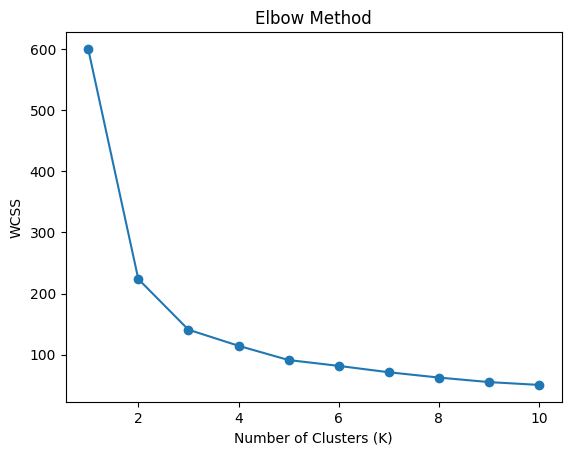

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  


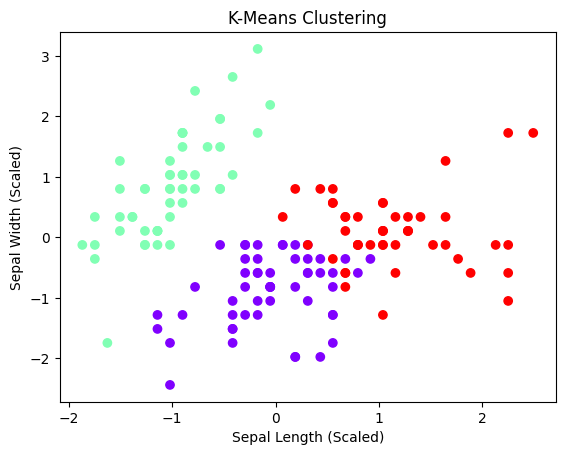

In [ ]:

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 2: Load dataset
df = pd.read_csv("Iris.csv")

# Step 3: Select numerical features
X = df[['SepalLengthCm', 'SepalWidthCm',
        'PetalLengthCm', 'PetalWidthCm']]

# Step 4: Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Step 6: Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()

# Step 7: Apply K-Means with optimal K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_pred = kmeans.fit_predict(X_scaled)

# Step 8: Add cluster labels to dataset
df['Cluster'] = y_pred

print(df.head())

# Step 9: Visualize clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=y_pred, cmap='rainbow')

plt.title('K-Means Clustering')
plt.xlabel('Sepal Length (Scaled)')
plt.ylabel('Sepal Width (Scaled)')
plt.show()
